# Radius perturbation

Keep a T-cell center fixed and replace neighbor expression from the outside inward. This small example follows the distance-ranked donor replacement in the research evaluation, using the epoch-10 student and a complete UPMC-HNC internal-validation region.

We use 32 T-cell centers and two donors per center, each disjoint from its recipient. All T-cell subtypes are eligible. The example demonstrates the computation, not the full-cohort spatial-range estimates.

From the repository root, use the tested Python 3.12 environment:
```bash
python -m pip install -r requirements-tutorials.txt -c constraints-tutorials.txt
python scripts/download_checkpoint.py
```

In [1]:
from pathlib import Path
import copy
import json
import sys
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sober/config.py").is_file())
sys.path.insert(0, str(ROOT))
from sober.checkpoint import load_checkpoint, file_sha256
from sober.data_loader import SpatialBiomarkerDataset
from sober.cell_type_normalize import apply_cell_type_normalization
from sober.spatial_sampler import SpatialSampler
from sober.evaluation import verify_example_files
from sober.perturbation import (center_masks, predict_center_markers, match_donors,
                                radial_plan, replace_outside_radius, radial_summary)

SEED, N_CENTERS, N_POOL, N_DONORS = 42, 32, 128, 2
BATCH_SIZE = 16
MODEL_UNITS_PER_UM = 2.0
RADIUS_UM = 150.
BOUNDARIES_UM = np.array([150., 75., 50., 37.5, 25., 12.5, 0.])
READOUTS = ["GranzymeB", "CD45RA"]
torch.set_num_threads(2)
model_info = json.loads((ROOT / "models/epoch10.json").read_text())
model, checkpoint = load_checkpoint(ROOT / "checkpoints/sober_epoch10.pth", device="cpu",
                                    expected_sha256=model_info["sha256"])
%matplotlib inline
plt.rcParams.update({"font.size": 10, "figure.dpi": 120,
                     "axes.spines.top": False, "axes.spines.right": False})
print(f"Epoch {checkpoint['epoch']} student | CPU")

Loaded 41 biomarkers from sober/assets/biomarker_sequences.csv
Loaded 1282 biomarker aliases
Building biomarker vocabulary using learnable method...
Processing 41 valid biomarkers (EMPTY ones filtered out)
Building learnable embeddings...


Epoch 10 student | CPU


## Select real neighborhoods

Retain the full region for normalization and neighbor lookup. Centers are sampled without replacement from the standardized coarse **T cells** annotation. An additional random pool expands donor candidates; all sampled neighborhoods are eligible donors. Selection does not use predictions.

Neighbors are capped at 100 within **150 µm**. We follow the research conversion of two stored coordinate units per micrometre. Model inputs retain their original coordinates; plots and exported distances use µm.

In [2]:
manifest = json.loads((ROOT / "examples/data/manifest.json").read_text())
example = manifest["downstream_examples"]
record = example["query"]
verify_example_files(ROOT / "examples/data", [record])
assert example["recorded_split"]["source_sha256"] == checkpoint["provenance"]["training_split_sha256"]
role = next(r for r in example["recorded_split"]["regions"]
            if (r["study"], r["region"]) == (record["study"], record["region"]))
assert role["partition"] == "validation"

config = copy.deepcopy(model.config)
config.use_cell_types = True
config.neighbor_distance_threshold = RADIUS_UM * MODEL_UNITS_PER_UM
config.max_neighbors = 100
config.cell_type_mapping_file = str(ROOT / "sober/assets/cell_type_mappings.csv")
assert Path(config.cell_type_mapping_file).read_text() == checkpoint["assets"]["cell_type_mapping_file"]["text"]
data = SpatialBiomarkerDataset(ROOT / "examples/downstream", config)
apply_cell_type_normalization(data, verbose=False)
region = next(r for r in data.regions if r["region_name"] == record["region"])
assert set(region["biomarkers"]) <= set(checkpoint["biomarker_vocab"])
eligible = [i for i, h in enumerate(region["cell_type_hierarchy"]) if h and h[0] == "T cells"]
rng = np.random.RandomState(SEED)
center_indices = sorted(rng.choice(eligible, N_CENTERS, replace=False).tolist())
remaining = sorted(set(range(region["num_cells"])) - set(center_indices))
pool_indices = sorted(rng.choice(remaining, N_POOL, replace=False).tolist())
indices = sorted(center_indices + pool_indices)
sampler = SpatialSampler(config)
samples = [sampler.sample_region_at(region, i) for i in indices]
recipients = [indices.index(i) for i in center_indices]
print(f"{region['num_cells']:,} source cells; {len(eligible)} eligible T cells; "
      f"{len(recipients)} centers and {len(pool_indices)} pool centers")

Loaded cell-type version table: 22 studies from sober/assets/study_celltype_final.tsv
Loaded 1 regions; skipped 0 small regions
1,673 source cells; 347 eligible T cells; 32 centers and 128 pool centers


## Match donors and fix the masks

Match within study and marker panel using neighbor count, radius, broad cell-type composition and neighborhood typicality. Donor and recipient neighborhoods must not share cells. This single-region example uses the original same-region fallback; candidate-pool size and donor count are reduced for the tutorial.

The research default forces every non-primer, non-DAPI response marker into the center mask. Here **CD3e and DAPI remain visible**, and the other 39 markers are hidden. The nominal 80% ratio is a minimum when the forced targets exceed it. Neighbors remain unmasked. The same mask is reused at every boundary and donor.

In [3]:
assignments = match_donors(samples, recipients, n_donors=N_DONORS, seed=SEED)
originals = [samples[i] for i in recipients]
mask_targets = [m for m in region["biomarkers"] if m not in {"CD3e", "DAPI"}]
masks = center_masks(originals, targets=mask_targets, visible=("CD3e",), seed=SEED + 201)
plans, donor_rows = [], []
for pos, recipient in enumerate(recipients):
    for slot, donor in enumerate(assignments[recipient]):
        plan = radial_plan(samples[recipient], samples[donor])
        assert not set(samples[recipient]["cell_ids"]) & set(samples[donor]["cell_ids"])
        plans.append((pos, donor, slot, plan))
        donor_rows.append({"center_idx": indices[recipient], "center_cell_id": str(samples[recipient]["cell_ids"][0]),
                           "donor_slot": slot, "donor_idx": indices[donor],
                           "donor_cell_id": str(samples[donor]["cell_ids"][0])})
donors = pd.DataFrame(donor_rows)
print(f"{len(plans)} donor assignments; {len(masks[0])}/{len(region['biomarkers'])} center markers hidden")
display(donors.head())

64 donor assignments; 39/41 center markers hidden


,center_idx,center_cell_id,donor_slot,donor_idx,donor_cell_id
0,187,1110100,0,291,1110204
1,187,1110100,1,955,1110868
2,394,1110307,0,1078,1110991
3,394,1110307,1,1304,1111217
4,524,1110437,0,238,1110151


## Replace expression outside each boundary

Pair recipient and donor neighbors by distance rank once, then reuse that pairing. The boundary starts at **150 µm**, the unperturbed baseline, and moves inward. At boundary `b` µm, only recipient slots farther than `b` are replaced. Recipient positions, cell count and center expression stay fixed; the operation does not transplant donor coordinates or crop the neighborhood.

The reconstruction head predicts the same hidden center markers in every condition.

In [4]:
baseline = predict_center_markers(model, originals, masks, READOUTS, BATCH_SIZE)
rows = []
for boundary_um in BOUNDARIES_UM:
    changed, fixed_masks, n_replaced = [], [], []
    for pos, donor, slot, plan in plans:
        edited, count = replace_outside_radius(originals[pos], samples[donor], plan, boundary_um * MODEL_UNITS_PER_UM)
        np.testing.assert_array_equal(edited["coordinates"], originals[pos]["coordinates"])
        np.testing.assert_array_equal(edited["intensities"][0], originals[pos]["intensities"][0])
        changed.append(edited)
        fixed_masks.append(masks[pos])
        n_replaced.append(count)
    predicted = predict_center_markers(model, changed, fixed_masks, READOUTS, BATCH_SIZE)
    if boundary_um == RADIUS_UM:
        assert not any(n_replaced)
        np.testing.assert_allclose(predicted, np.stack([baseline[p] for p, _, _, _ in plans]), atol=2e-5, rtol=1e-5)
    for j, (pos, donor, slot, _) in enumerate(plans):
        sample = originals[pos]
        for k, marker in enumerate(READOUTS):
            rows.append({"center_idx": sample["original_center_idx"], "cell_id": str(sample["cell_ids"][0]),
                         "donor_slot": slot, "donor_idx": samples[donor]["original_center_idx"],
                         "boundary": float(boundary_um), "marker": marker,
                         "observed": float(sample["intensities"][0, sample["biomarkers"].index(marker)]),
                         "original_prediction": float(baseline[pos, k]), "predicted": float(predicted[j, k]),
                         "replaced_fraction": n_replaced[j] / (len(sample["intensities"]) - 1)})
predictions = pd.DataFrame(rows)
summary = radial_summary(predictions).rename(columns={"boundary": "boundary_um"})
predictions = predictions.rename(columns={"boundary": "boundary_um"})
display(summary.loc[summary.boundary_um.isin([RADIUS_UM, BOUNDARIES_UM.min()])])

,marker,boundary_um,pearson_r,n_centers,n_valid_donor_slots,mean_replaced_fraction,pearson_drop
0,CD45RA,150.0,0.331694,32,2,0.0,0.000000
6,CD45RA,0.0,0.047200,32,2,1.0,0.284493
7,GranzymeB,150.0,0.224922,32,2,0.0,0.000000
13,GranzymeB,0.0,0.001793,32,2,1.0,0.223129


## Read the radius response

At each boundary, correlate predicted and observed center intensities across recipients separately for each donor slot, then average correlations in Fisher space. The plotted drop is the original correlation minus the perturbed correlation; negative values mean correlation increased. Averaging predictions before computing correlations would change this endpoint.

The two markers and all selected centers are retained regardless of effect direction. These are model sensitivities, not measured responses to a biological intervention.

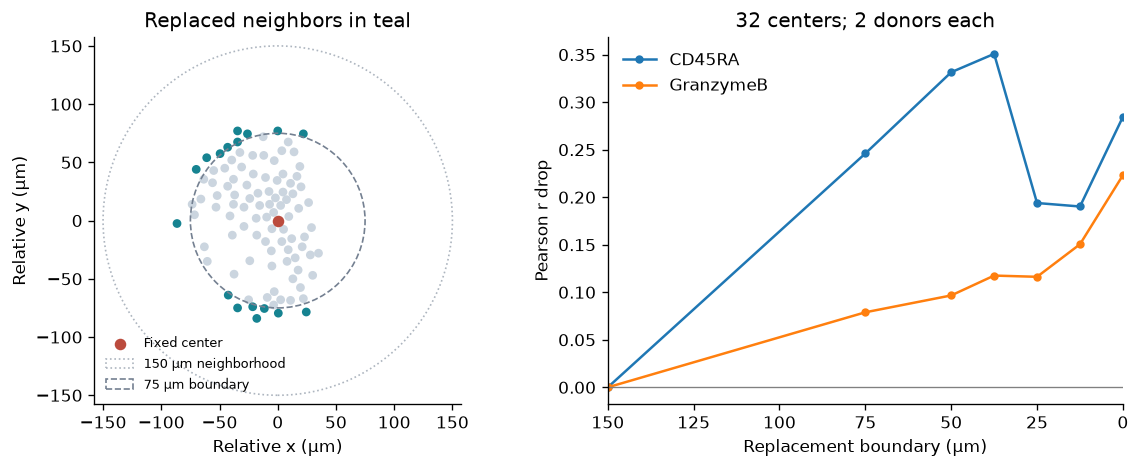

In [5]:
pos, donor, _, plan = plans[0]
shown_boundary_um = 75.
xy_um = np.asarray(originals[pos]["coordinates"]) / MODEL_UNITS_PER_UM
changed_slots = np.linalg.norm(xy_um[1:], axis=1) > shown_boundary_um
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(xy_um[1:, 0], xy_um[1:, 1],
                c=np.where(changed_slots, "#168391", "#cbd5df"), s=18)
axes[0].scatter(*xy_um[0], c="#bb4b3d", s=35, label="Fixed center")
axes[0].add_patch(plt.Circle((0, 0), RADIUS_UM, fill=False, ls=":", color="#adb5bf",
                             label="150 µm neighborhood"))
axes[0].add_patch(plt.Circle((0, 0), shown_boundary_um, fill=False, ls="--", color="#748091",
                             label=f"{shown_boundary_um:g} µm boundary"))
axes[0].set(aspect="equal", xlabel="Relative x (µm)", ylabel="Relative y (µm)",
            xlim=(-RADIUS_UM * 1.05, RADIUS_UM * 1.05), ylim=(-RADIUS_UM * 1.05, RADIUS_UM * 1.05),
            title="Replaced neighbors in teal")
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
for marker, frame in summary.groupby("marker", sort=False):
    axes[1].plot(frame.boundary_um, frame.pearson_drop, "o-", ms=4, label=marker)
axes[1].axhline(0, color="0.5", lw=0.8)
axes[1].set(xlim=(RADIUS_UM, 0), xticks=np.arange(0, RADIUS_UM + 1, 25),
            xlabel="Replacement boundary (µm)", ylabel="Pearson r drop",
            title=f"{N_CENTERS} centers; {N_DONORS} donors each")
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

## Save the run

The export includes the sampled cells, donor pairings, center masks and predictions. To inspect a different distance grid, change `BOUNDARIES_UM` while retaining 150 µm as the unperturbed boundary, then rerun from the top.

In [6]:
OUT = ROOT / "outputs/radius_perturbation"
OUT.mkdir(parents=True, exist_ok=True)
predictions.to_csv(OUT / "predictions.csv", index=False)
summary.to_csv(OUT / "radius_summary.csv", index=False)
donors.to_csv(OUT / "donors.csv", index=False)
fig.savefig(OUT / "radius_response.png", dpi=180, bbox_inches="tight")
run = {"checkpoint_sha256": model_info["sha256"], "weights": "student", "region": record["region"],
       "data_sha256": {name: info["sha256"] for name, info in record["files"].items()},
       "seed": SEED, "sampling_radius_um": RADIUS_UM, "max_neighbors": config.max_neighbors,
       "distance_unit": "µm", "model_units_per_um": MODEL_UNITS_PER_UM, "boundaries_um": BOUNDARIES_UM.tolist(),
       "readouts": READOUTS, "center_indices": center_indices, "pool_indices": pool_indices,
       "center_masks": [mask.tolist() for mask in masks], "n_donors": N_DONORS,
       "source_code_sha256": file_sha256(ROOT / "sober/perturbation.py"),
       "packages": {name: version(name) for name in ["torch", "numpy", "pandas", "scipy"]}}
(OUT / "evaluation.json").write_text(json.dumps(run, indent=2) + "\n")
print("Saved predictions, donor pairs, masks and radius responses to outputs/radius_perturbation")

Saved predictions, donor pairs, masks and radius responses to outputs/radius_perturbation
